# 01_EDA — Inteligencia musical y predicción de hits

**EV3 · MLY1101 · Caso C · CRISP-DM: comprensión y preparación de los datos**

Continuación del proyecto [EV2_ML](https://github.com/carlos31255/EV2_ML). Se mantiene su estructura y definición de hit, con un EDA exclusivamente sobre train. El test se reserva antes de explorar; no se calculan sus distribuciones ni métricas.

**Pregunta de negocio:** ¿qué canciones priorizar para una campaña de promoción? La etiqueta es popularidad ≥ P80 de train: es una definición relativa del dataset, no una garantía de éxito comercial futuro.

**Hipótesis EV3:** comparar género completo, ausencia de género y representación reducida con PCA. PCA no garantiza equidad ni mejor predicción. LazyPredict, PCA, K-Means y modelación se desarrollarán en notebooks posteriores.

KPIs heredados a contrastar posteriormente: AUC ≥ 0,80; recall ≥ 0,75; lift@10% ≥ 2; gap AUC train/evaluación < 0,05. Son metas del equipo. También se reportarán precisión, average precision, variabilidad de CV y errores por género.

## 1. Entorno y rutas
Coloca `Spotify_Tracks_Dataset.csv` en `data/raw/`. Ejecuta **Restart Kernel & Run All**. Las funciones reutilizables viven en `src/`; los gráficos en `output/graficos/` y las tablas en `output/tablas/`. No se necesita ejecutar otro notebook antes.

In [11]:
from pathlib import Path
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/pipeline.py").is_file() and (p / "notebooks").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Abre el notebook dentro de la carpeta EV3_ML.")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src import graficos as gr
from src.pipeline import (generar_split_raw, aplicar_transformaciones, generar_processed,
                          FEATURES_SCALE, FEATURES_TEXT_NUM, FEATURES_TEXT_BIN)
TABLAS = ROOT / "output/tablas"
TABLAS.mkdir(parents=True, exist_ok=True)
print("Raíz:", ROOT)

Raíz: f:\DUOC\Machine Learning\EV3


## 2. Limpieza estructural y separación train/test
Antes de explorar se aplican reglas heredadas de EV2: eliminar nulos críticos, consolidar por `track_id` conservando todos los géneros y popularidad máxima entre copias, y construir `song_key` con artista+título normalizados. Estas reglas se fijan antes del EDA.

`GroupShuffleSplit(test_size=0.20, random_state=42)` separa grupos, por lo que el porcentaje de filas puede no ser exactamente 80/20. La clave agrupa coincidencias de artista+título; no detecta automáticamente todos los remixes, títulos alternativos o artistas nuevos.

Se guarda una huella del dataset, configuración y archivos del split. Una segunda ejecución reutiliza el split y rechaza cambios silenciosos. **No se selecciona la semilla según resultados ni se estratifica usando test.**

In [2]:
train_raw, test_reservado = generar_split_raw()
assert set(train_raw.track_id).isdisjoint(test_reservado.track_id)
assert set(train_raw.song_key).isdisjoint(test_reservado.song_key)
resumen_split = pd.DataFrame({"conjunto": ["train", "test reservado"],
                              "filas": [len(train_raw), len(test_reservado)]})
display(resumen_split)
resumen_split.to_csv(TABLAS / "01_split.csv", index=False)
del test_reservado  # no disponible para explorar en las siguientes celdas
print("Sin track_id ni song_key compartidos. Test reservado.")

[pipeline] Cargando raw data...
[pipeline] Eliminando nulos criticos...
[pipeline] Construyendo song_key para el split (artists + track_name)...
[pipeline] Agrupando generos y calculando max popularity por track_id...
[pipeline] Haciendo split agrupado (GroupShuffleSplit) sobre song_key...
[pipeline] Raw Train: 71706, Raw Test: 18034


,conjunto,filas
0,train,71706
1,test reservado,18034


Sin track_id ni song_key compartidos. Test reservado.


## 3. Calidad de datos en train
Inspeccionamos tipos, faltantes, rangos y duplicados. Los nulos en predictores no se imputan aquí: la imputación se aprenderá dentro de cada fold en modelación. Los valores extremos no se eliminan automáticamente.

In [3]:
display(train_raw.head())
calidad = pd.DataFrame({"tipo": train_raw.dtypes.astype(str),
                       "nulos": train_raw.isna().sum(),
                       "porcentaje_nulos": train_raw.isna().mean().mul(100),
                       "valores_distintos": train_raw.nunique()})
display(calidad)
calidad.to_csv(TABLAS / "02_calidad_train.csv")
display(train_raw[gr.NUM_COLS + ["popularity"]].describe().T)
print("track_id duplicados en train:", train_raw.track_id.duplicated().sum())
unitarias = ["danceability", "energy", "valence", "acousticness", "speechiness", "instrumentalness", "liveness"]
display(pd.Series({c: int((train_raw[c].notna() & ~train_raw[c].between(0, 1)).sum())
                   for c in unitarias}, name="fuera_de_0_1").to_frame())

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,...,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,song_key,n_generos,grupo
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.461,1,...,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic|j-pop|singer-songwriter|songwriter,gen hoshino||comedy,4,gen hoshino||comedy
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.166,1,...,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic|chill,ben woodward||ghost - acoustic,2,ben woodward||ghost - acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.443,2,...,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,chord overstreet||hold on,1,chord overstreet||hold on
7,1EzrEOXmMH3G43AXT1y7pA,Jason Mraz,We Sing. We Dance. We Steal Things.,I'm Yours,80,242946,False,0.703,0.444,11,...,0.5590,0.000000,0.0973,0.712,150.960,4,acoustic|rock,jason mraz||i'm yours,2,jason mraz||i'm yours
8,0IktbUcnAGrvD03AWnz3Q8,Jason Mraz;Colbie Caillat,We Sing. We Dance. We Steal Things.,Lucky,74,189613,False,0.625,0.414,0,...,0.2940,0.000000,0.1510,0.669,130.088,4,acoustic,jason mraz;colbie caillat||lucky,1,jason mraz;colbie caillat||lucky


,tipo,nulos,porcentaje_nulos,valores_distintos
track_id,object,0,0.0,71706
artists,object,0,0.0,27039
album_name,object,0,0.0,39619
track_name,object,0,0.0,59612
popularity,int64,0,0.0,101
duration_ms,int64,0,0.0,43162
explicit,bool,0,0.0,2
danceability,float64,0,0.0,1135
energy,float64,0,0.0,1996
key,int64,0,0.0,12


,count,mean,std,min,25%,50%,75%,max
danceability,71706.0,0.562209,0.176436,0.000000,0.45000,0.576000,0.6910,0.985
energy,71706.0,0.633684,0.256500,0.000019,0.45700,0.676000,0.8520,1.000
loudness,71706.0,-8.507571,5.206667,-49.531000,-10.34900,-7.192000,-5.1280,4.532
valence,71706.0,0.469391,0.262838,0.000000,0.24900,0.458000,0.6820,0.994
tempo,71706.0,121.936468,30.111213,0.000000,99.08725,121.995000,140.0570,243.372
acousticness,71706.0,0.328447,0.338296,0.000000,0.01730,0.188000,0.6260,0.996
speechiness,71706.0,0.087307,0.113474,0.000000,0.03590,0.048900,0.0853,0.965
instrumentalness,71706.0,0.173946,0.324179,0.000000,0.00000,0.000061,0.1000,1.000
liveness,71706.0,0.216259,0.194680,0.000000,0.09800,0.132000,0.2770,1.000
duration_ms,71706.0,229310.936825,111668.230702,13386.000000,173172.00000,213324.500000,264516.5000,5237295.000


track_id duplicados en train: 0


,fuera_de_0_1
danceability,0
energy,0
valence,0
acousticness,0
speechiness,0
instrumentalness,0
liveness,0


## 4. Variable objetivo y balance de clases
El P80 se calcula solo con train y queda fijado para transformar el test al exportar. Por empates, la proporción de hits puede superar el 20%. `popularity` nunca entra en X, porque define directamente el objetivo.

Se mantienen los ceros: no hay evidencia suficiente para imputarlos como popularidad desconocida. El análisis posterior documenta su concentración.

[pipeline] Umbral de popularidad (P80) calculado en TRAIN: 52.0


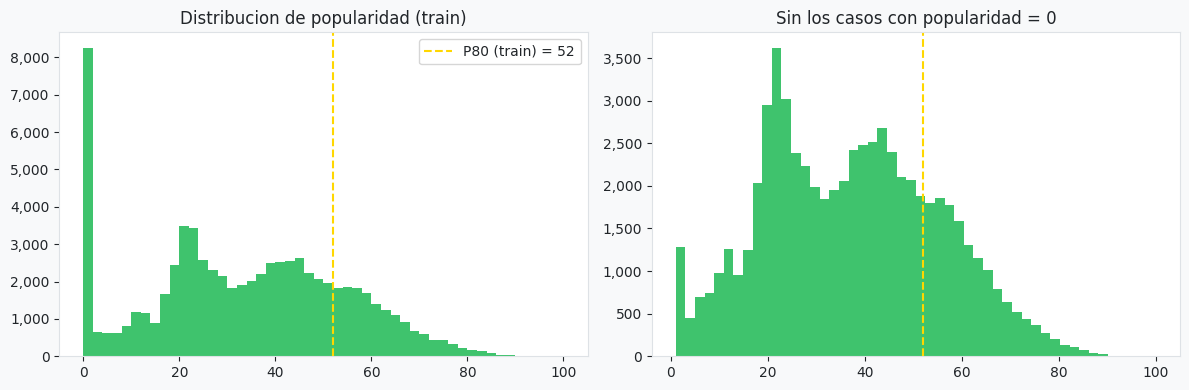

[graficos] Guardado: output\graficos\01_distribucion_popularidad.png


,n,porcentaje
hit,,
0,56639,78.987811
1,15067,21.012189


P80 de train: 52; hits: 21.01%; popularidad cero: 10.27%


In [4]:
df, umbral = aplicar_transformaciones(train_raw)
gr.grafico_distribucion_popularidad(df, umbral)
balance = df.hit.value_counts().sort_index().rename("n").to_frame()
balance["porcentaje"] = balance.n / len(df) * 100
display(balance)
balance.to_csv(TABLAS / "03_balance_train.csv")
print(f"P80 de train: {umbral:g}; hits: {df.hit.mean():.2%}; popularidad cero: {df.popularity.eq(0).mean():.2%}")

## 5. Audio: distribuciones, asimetría y valores extremos
Conservamos como candidatos los `log1p` de EV2: `speechiness`, `instrumentalness`, `liveness` y `duration_ms`. Son transformaciones deterministas; se compara su efecto en train. `loudness` puede ser negativo y no recibe log1p. No se promete normalidad ni mejora para todos los modelos.

La regla IQR solo identifica observaciones para inspección; no demuestra que sean errores. Escalado y PCA no se ajustan en este notebook.

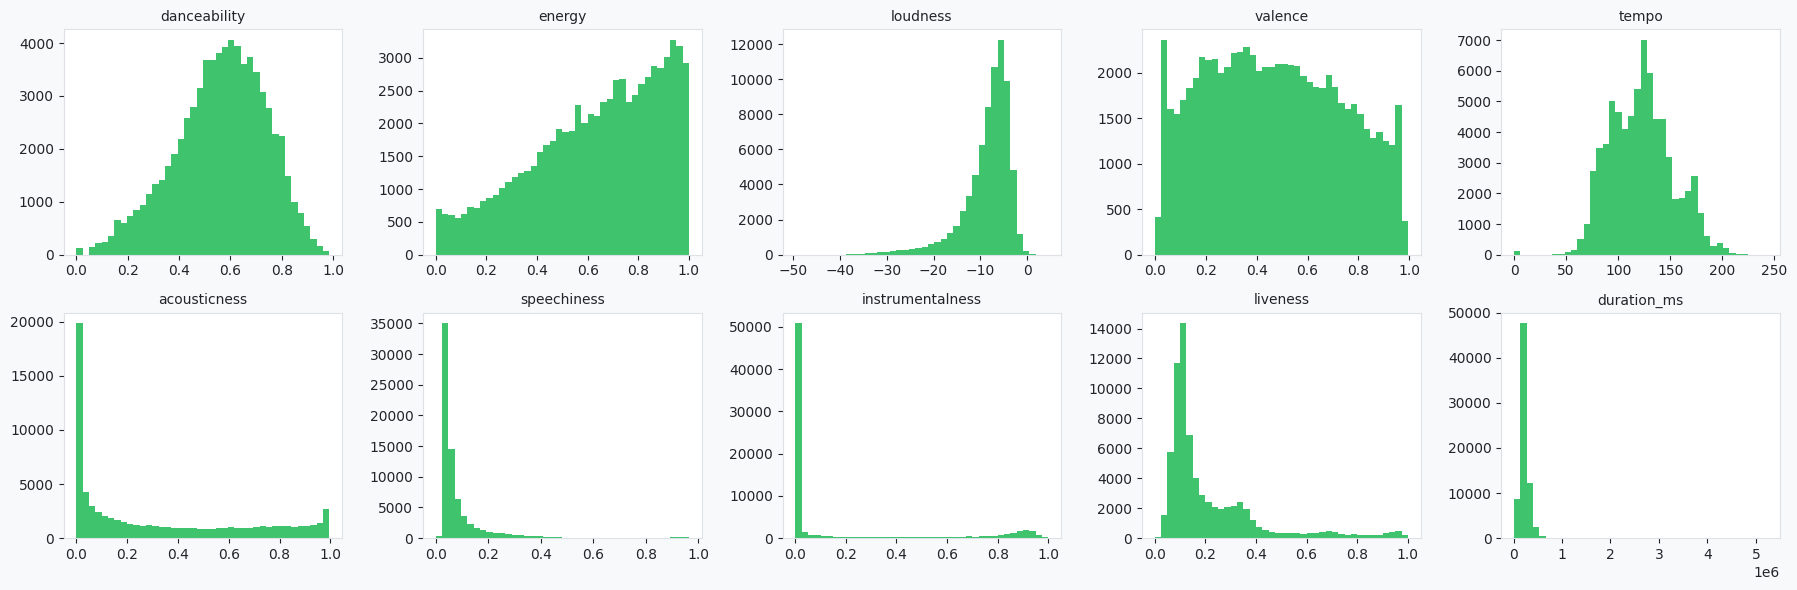

[graficos] Guardado: output\graficos\02_distribuciones_numericas.png


,original,log1p
speechiness,4.542150,3.676612
instrumentalness,1.559547,1.482455
liveness,2.072237,1.716798
duration_ms,10.391775,-0.323272


,porcentaje_fuera_IQR
danceability,0.556439
energy,0.000000
loudness,5.519761
valence,0.000000
tempo,0.581541
acousticness,0.000000
speechiness,11.869300
instrumentalness,21.885198
liveness,7.840348
duration_ms,4.759713


In [5]:
gr.grafico_distribuciones_numericas(df)
log_vars = ["speechiness", "instrumentalness", "liveness", "duration_ms"]
asimetria = pd.DataFrame({"original": df[log_vars].skew(),
    "log1p": [df[c + "_log"].skew() for c in log_vars]})
display(asimetria)
asimetria.to_csv(TABLAS / "04_asimetria_train.csv")
q1, q3 = df[gr.NUM_COLS].quantile(.25), df[gr.NUM_COLS].quantile(.75)
iqr = q3 - q1
extremos = ((df[gr.NUM_COLS] < q1 - 1.5*iqr) | (df[gr.NUM_COLS] > q3 + 1.5*iqr)).mean().mul(100)
display(extremos.rename("porcentaje_fuera_IQR").to_frame())

## 6. Géneros y relación descriptiva con hit
Una canción multigénero cuenta en cada género: los grupos se solapan y sus tamaños no se deben sumar como canciones únicas. Se presentan tasas y soporte, sin evaluar AUC en test.

Diferencias de tasas no demuestran causalidad ni por sí solas discriminación del modelo. Motivan los experimentos con/sin género y PCA. La representación multi-hot se generará con un vocabulario aprendido en train. No se selecciona aún el número de componentes.

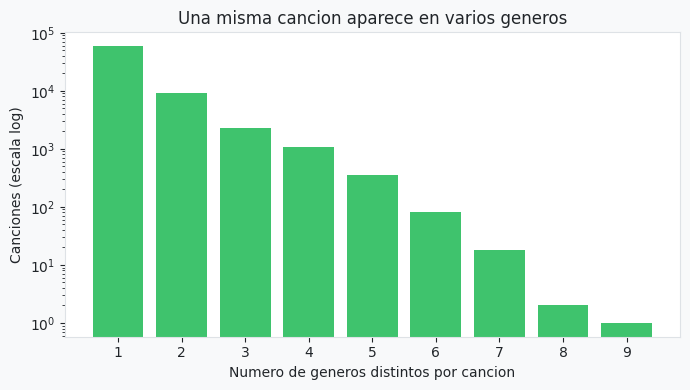

[graficos] Guardado: output\graficos\00_generos_por_cancion.png


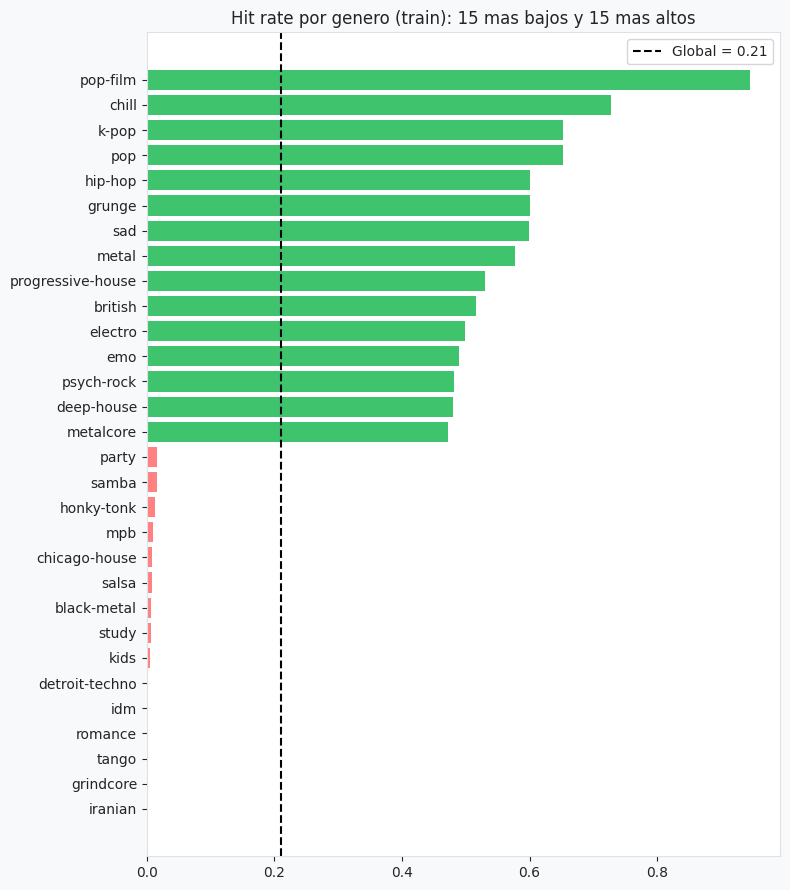

[graficos] Guardado: output\graficos\03_hit_rate_por_genero.png


,hit_rate,n,hits
genero,,,
iranian,0.000000,803,0
grindcore,0.000000,781,0
tango,0.000000,810,0
romance,0.000000,728,0
idm,0.001271,787,1
...,...,...,...
hip-hop,0.601342,745,448
pop,0.652447,797,520
k-pop,0.653186,816,533


Canciones multigénero: 18.05%
Géneros observados en train: 114


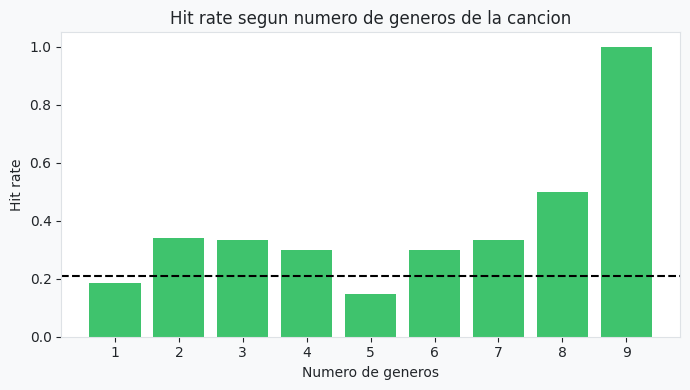

[graficos] Guardado: output\graficos\04_hit_rate_n_generos.png


,hit_rate,n
n_generos,,
1,0.184,58763
2,0.340,9138
3,0.333,2301
4,0.298,1055
5,0.147,348
6,0.300,80
7,0.333,18
8,0.500,2
9,1.000,1


In [6]:
gr.grafico_generos_por_cancion(df.n_generos.value_counts().sort_index())
tasa = gr.grafico_hit_rate_genero(df)
tasa["hits"] = (tasa.hit_rate * tasa.n).round().astype(int)
display(tasa)
tasa.to_csv(TABLAS / "05_generos_train.csv")
print(f"Canciones multigénero: {df.n_generos.gt(1).mean():.2%}")
print(f"Géneros observados en train: {len(tasa)}")
por_numero = gr.grafico_hit_rate_n_generos(df)
display(por_numero)
por_numero.to_csv(TABLAS / "06_numero_generos_train.csv")

`n_generos` queda como variable de auditoría, no como predictor explícito, por la hipótesis heredada de EV2 de que el número de etiquetas pueda reflejar el proceso de recopilación o la popularidad. Esta hipótesis no queda probada por el EDA. El multi-hot conserva el conteo implícitamente y PCA no garantiza eliminarlo.

No se interpretan tasas de grupos pequeños como estimaciones precisas. La comparación entre modelos deberá incluir resultados por género y soporte suficiente.

## 7. Variables predictoras y relaciones con el objetivo
Las correlaciones no miden relaciones causales ni todas las interacciones no lineales. No se descarta audio por correlación marginal baja. `key` y `time_signature` se examinan como categorías, sin interpretar sus códigos como una escala continua.

Se conservan las variables simples de texto de EV2: número de artistas, palabras del título y marcas remix/live/feat. No se usa la identidad del artista, título o álbum como predictor.

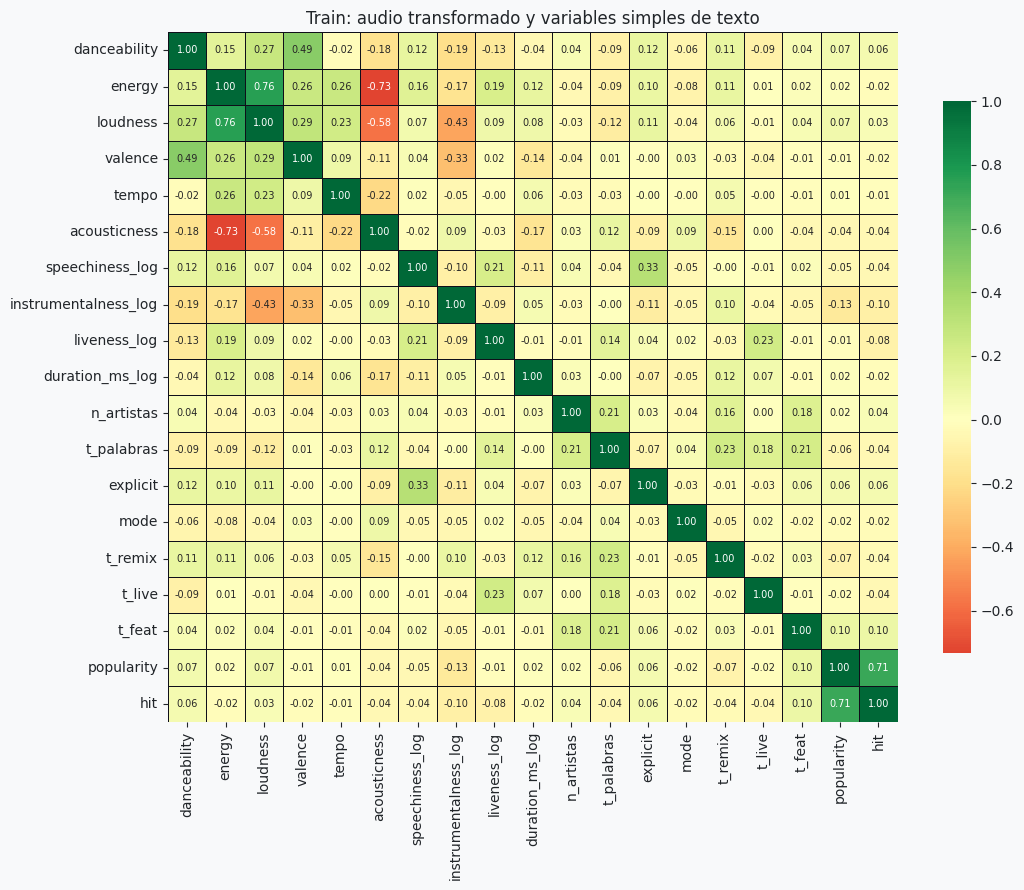

[graficos] Guardado: output\graficos\05_correlaciones.png


,pearson,spearman
instrumentalness_log,-0.095611,-0.070503
liveness_log,-0.083004,-0.058664
t_live,-0.043228,-0.043228
t_palabras,-0.043635,-0.041736
speechiness_log,-0.042912,-0.035818
t_remix,-0.035091,-0.035091
duration_ms_log,-0.021520,-0.032677
energy,-0.017822,-0.028689
mode,-0.024378,-0.024378
valence,-0.020469,-0.018122


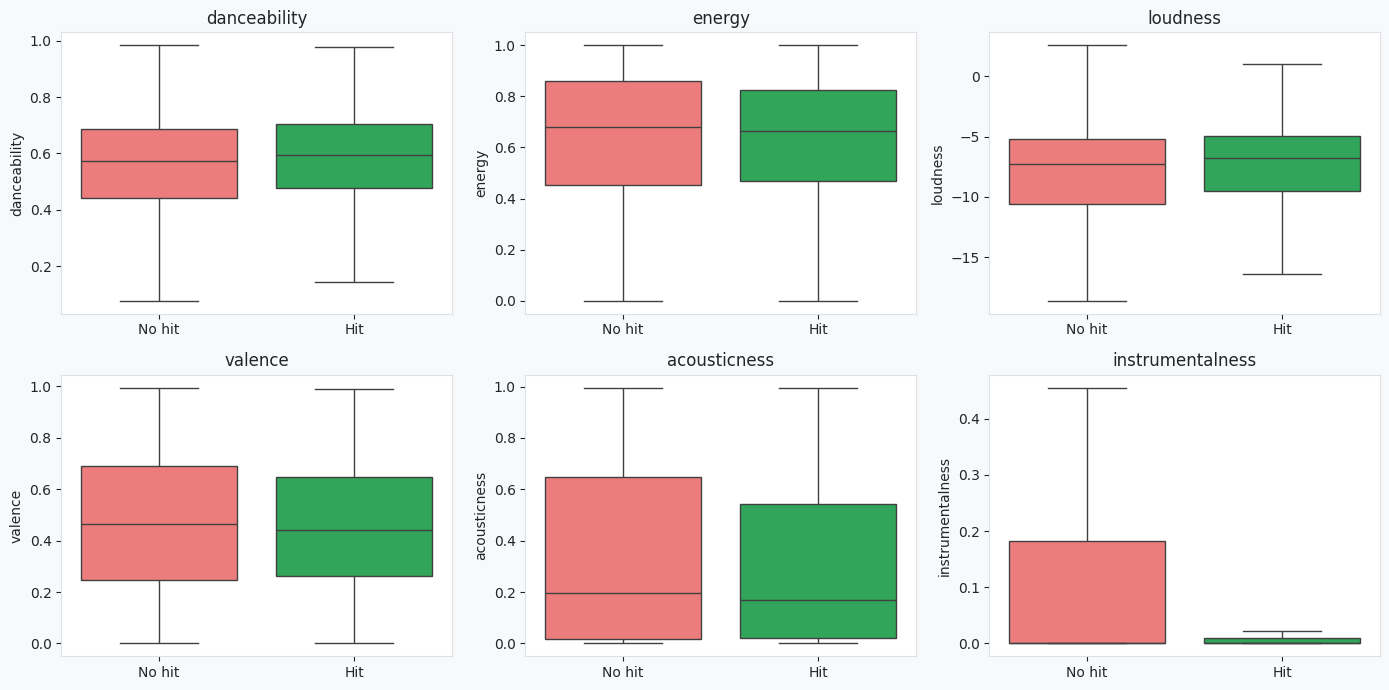

[graficos] Guardado: output\graficos\06_features_por_clase.png
key


,hit_rate,n
key,,
0,0.205760,8194
1,0.222351,6899
2,0.196624,7405
3,0.227882,2238
4,0.207606,5732
5,0.216458,5821
6,0.229897,4937
7,0.184335,8452
8,0.240683,4508


time_signature


,hit_rate,n
time_signature,,
0,0.076923,130
1,0.146051,671
3,0.168117,6091
4,0.216327,63538
5,0.148903,1276


explicit


,hit_rate,n
explicit,,
False,0.202038,65557
True,0.296308,6149


In [7]:
cols = FEATURES_SCALE + FEATURES_TEXT_NUM + ["explicit", "mode"] + FEATURES_TEXT_BIN
corr = gr.grafico_correlaciones(df, cols, nombre="05_correlaciones.png",
                                titulo="Train: audio transformado y variables simples de texto")
corr.to_csv(TABLAS / "07_correlaciones_train.csv")
comparacion = pd.DataFrame({"pearson": df[cols].corrwith(df.hit),
                           "spearman": df[cols].corrwith(df.hit, method="spearman")})
display(comparacion.sort_values("spearman"))
gr.grafico_features_por_clase(df)
for c in ["key", "time_signature", "explicit"]:
    print(c)
    display(df.groupby(c).hit.agg(hit_rate="mean", n="size"))

## 8. Géneros con mayor proporción de canciones con popularidad 0
El gráfico muestra los 15 géneros con mayor porcentaje de canciones con popularidad 0 y los compara con el porcentaje global de train, marcado por la línea discontinua. Esto permite identificar dónde se concentran los ceros.

Estos valores pueden representar baja popularidad real o limitaciones del dato; el dataset no permite distinguir ambas situaciones. Por ello, se conservan: eliminarlos podría alterar la representación de géneros y artistas.

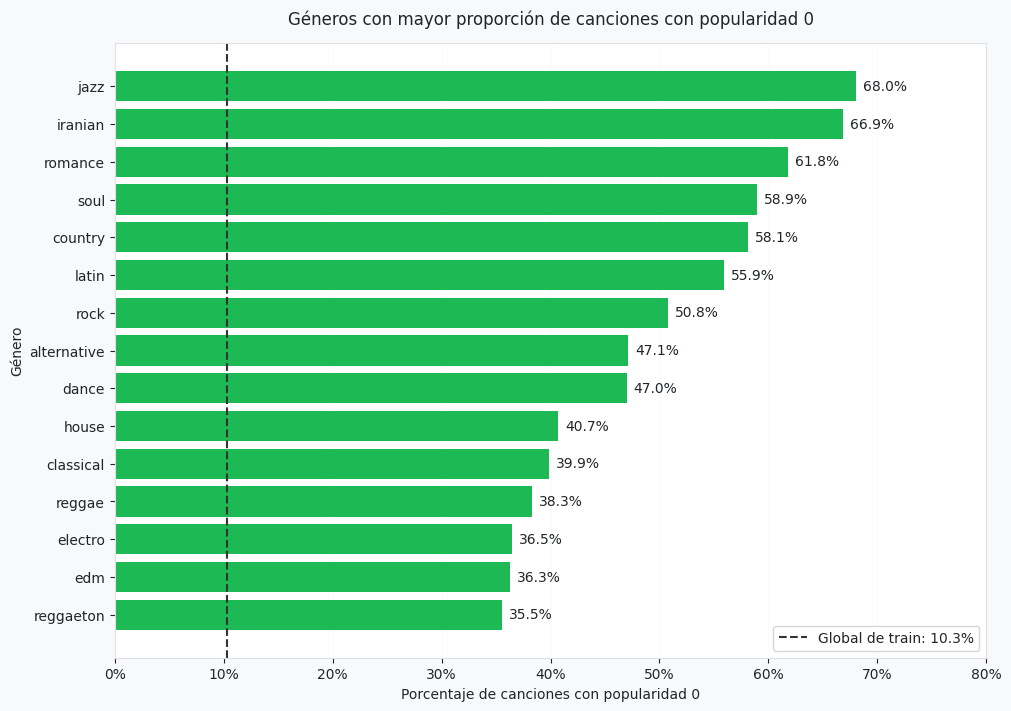

,proporcion_cero,canciones,canciones_cero
genero,,,
jazz,68.0%,822,559
iranian,66.9%,803,537
romance,61.8%,728,450
soul,58.9%,728,429
country,58.1%,816,474
latin,55.9%,792,443
rock,50.8%,791,402
alternative,47.1%,777,366
dance,47.0%,766,360


Artistas con al menos cinco canciones: 4957
De ellos, artistas con todas en popularidad cero: 121


,danceability,energy,loudness,valence,acousticness,instrumentalness
popularity,,,,,,
Popularidad mayor que 0,0.563157,0.640368,-8.456616,0.468222,0.321358,0.179092
Popularidad igual a 0,0.553926,0.575286,-8.952784,0.479609,0.390383,0.128984


In [13]:
# Una canción multigénero cuenta en cada uno de sus géneros.
por_genero = (
    df.assign(genero=df["track_genre"].str.split("|"))
      .explode("genero")
)

resumen_ceros = (
    por_genero.assign(cero=por_genero["popularity"].eq(0))
              .groupby("genero")
              .agg(
                  proporcion_cero=("cero", "mean"),
                  canciones=("cero", "size"),
                  canciones_cero=("cero", "sum"),
              )
              .sort_values("proporcion_cero", ascending=False)
)

# Los 15 géneros con mayor proporción de ceros.
top = resumen_ceros.head(15).sort_values("proporcion_cero")
proporcion_global = df["popularity"].eq(0).mean()

fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")

barras = ax.barh(
    top.index,
    top["proporcion_cero"],
    color="#1DB954",
)

ax.bar_label(
    barras,
    labels=[f"{valor:.1%}" for valor in top["proporcion_cero"]],
    padding=5,
    fontsize=10,
)

ax.axvline(
    proporcion_global,
    color="#333333",
    linestyle="--",
    linewidth=1.5,
    label=f"Global de train: {proporcion_global:.1%}",
)

ax.set_title(
    "Géneros con mayor proporción de canciones con popularidad 0",
    pad=14,
)
ax.set_xlabel("Porcentaje de canciones con popularidad 0")
ax.set_ylabel("Género")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_xlim(
    0,
    max(float(top["proporcion_cero"].max()), proporcion_global) + 0.12,
)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
ax.legend(loc="lower right")

ruta = ROOT / "output" / "graficos" / "07_popularidad_cero.png"
ruta.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(ruta, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

# Tabla completa: porcentajes y cantidad de canciones por género.
tabla = resumen_ceros.head(15).copy()
tabla["proporcion_cero"] = tabla["proporcion_cero"].map(
    lambda valor: f"{valor:.1%}"
)
display(tabla)

resumen_ceros.to_csv(
    TABLAS / "08_popularidad_cero_genero_train.csv"
)

# Análisis por artista, conservando el contenido original.
ex = (
    df[["artists", "hit", "popularity"]]
    .assign(artista=df["artists"].str.split(";"))
    .explode("artista")
)
ex["artista"] = ex["artista"].str.strip()

por_artista = (
    ex.assign(cero=ex["popularity"].eq(0))
      .groupby("artista")
      .agg(
          n=("hit", "size"),
          hit_rate=("hit", "mean"),
          proporcion_cero=("cero", "mean"),
      )
)

elegibles = por_artista.loc[por_artista["n"] >= 5]

print("Artistas con al menos cinco canciones:", len(elegibles))
print(
    "De ellos, artistas con todas en popularidad cero:",
    int(elegibles["proporcion_cero"].eq(1).sum()),
)

display(
    df.groupby(df["popularity"].eq(0))[gr.VARS_BOX]
      .mean()
      .rename(index={
          False: "Popularidad mayor que 0",
          True: "Popularidad igual a 0",
      })
)

## 9. Versiones de canciones y limitaciones del agrupamiento
Se analiza solo train. Popularidad máxima entre copias del mismo `track_id` replica la decisión de EV2 y puede elevar la etiqueta respecto de otras reglas de agregación. Distintos IDs con la misma clave artista+título permanecen en el mismo conjunto.

El split por canción **no** equivale a un split por artista ni temporal: no permite afirmar generalización a artistas inéditos o éxito futuro. No se consulta el solapamiento de artistas del test para tomar decisiones en este EDA.

In [9]:
versiones = df.groupby("song_key").agg(n=("track_id", "size"),
    popularidad_min=("popularity", "min"), popularidad_max=("popularity", "max"), clases=("hit", "nunique"))
print("Grupos con varios track_id:", int(versiones.n.gt(1).sum()))
print("Grupos con versiones en ambas clases:", int(versiones.clases.gt(1).sum()))
print("Grupos con diferencia de popularidad > 10:", int((versiones.popularidad_max-versiones.popularidad_min).gt(10).sum()))
versiones.loc[versiones.n.gt(1)].to_csv(TABLAS / "09_versiones_train.csv")

Grupos con varios track_id: 3783
Grupos con versiones en ambas clases: 1061
Grupos con diferencia de popularidad > 10: 1422


## 10. Exportación para modelación: mismas filas y mismo split
Se generan `X`, `y`, identificadores y grupos en `data/processed/train/` y `data/processed/test/`. El test recibe únicamente las transformaciones fijadas: P80 de train, logs, variables simples y vocabulario de géneros de train. No se muestran estadísticas suyas.

En esta exportación el multi-hot es una representación de referencia; para validación estricta posterior, el codificador deberá aprenderse dentro del fold (o usar una taxonomía externa predefinida), junto con imputación, escalado y PCA. Los CSV raw conservan las etiquetas de género necesarias para ello. Géneros desconocidos al transformar se ignoran sin crear columnas.

No se exporta una matriz ya escalada o reducida. LazyPredict usará una validación interna agrupada de train, nunca el test final.

In [10]:
res = generar_processed()
assert res["threshold"] == umbral
assert res["train_proc"].track_id.tolist() == train_raw.track_id.tolist()
X_train = pd.read_csv("data/processed/train/X_train.csv")
assert not {"popularity", "hit", "track_id", "artists", "track_name", "album_name", "n_generos"} & set(X_train.columns)
assert list(X_train.columns) == pd.read_csv("data/processed/test/X_test.csv", nrows=0).columns.tolist()
assert res["train_proc"][res["genre_cols"]].sum(axis=1).eq(res["train_proc"].n_generos).all()
print(f"Train listo: {len(X_train):,} filas, {X_train.shape[1]} variables; {len(res['genre_cols'])} columnas de género.")
print("Test exportado sin exploración. Metadatos: data/processed/preparacion.json")
del res  # también contiene el test transformado; no explorarlo

[pipeline] Aplicando transformaciones a Train...
[pipeline] Umbral de popularidad (P80) calculado en TRAIN: 52.0
[pipeline] Aplicando transformaciones a Test...
[pipeline] Guardando datos procesados...
[pipeline] Processed Train: 71706, Processed Test: 18034
[pipeline] Trazabilidad OK: processed = mismas filas que raw (mismo orden).
Train listo: 71,706 filas, 133 variables; 114 columnas de género.
Test exportado sin exploración. Metadatos: data/processed/preparacion.json


## Hallazgos de esta ejecución

- **Separación de datos:** se analizaron 71.706 canciones de train y se reservaron 18.034 para test, sin `track_id` ni `song_key` compartidos. El EDA se realizó exclusivamente sobre train.

- **Calidad:** después de la limpieza, train no presenta valores nulos ni duplicados de `track_id`. Las siete variables de audio revisadas con rango esperado entre 0 y 1 no presentan valores fuera de ese intervalo. Esto no garantiza que todos los registros estén libres de errores.

- **Variable objetivo:** el P80 de train es 52. Se identificaron 15.067 hits (21,01 %) y 56.639 no-hits (78,99 %). La proporción supera el 20 % por los empates en el umbral.

- **Popularidad cero:** representa el 10,27 % de train, pero su frecuencia varía considerablemente entre géneros. Destacan jazz (68,0 %), iranian (66,9 %) y romance (61,8 %). Además, 121 de los 4.957 artistas con al menos cinco canciones tienen todas sus canciones con popularidad cero. Estos resultados no permiten distinguir entre baja popularidad real y limitaciones del dato.

- **Géneros:** se observaron 114 géneros y un 18,05 % de canciones multigénero. Las tasas de hit por género varían entre 0 % y 94,55 %. Estas diferencias motivan comparar representaciones del género, pero no prueban causalidad ni que PCA mejore el modelo.

- **Número de géneros:** las canciones de un género presentan una tasa de hit del 18,4 %, frente al 34,0 % y 33,3 % en canciones de dos y tres géneros. La relación no es creciente en todos los grupos; las tasas de grupos con muy pocas canciones no son concluyentes.

- **Transformaciones y extremos:** `log1p` reduce especialmente la asimetría de duración, de 10,39 a −0,32. Su efecto es menor en speechiness, instrumentalness y liveness. La regla IQR marca un 21,89 % de instrumentalness y un 11,87 % de speechiness como valores extremos, pero esto no demuestra que sean errores.

- **Relaciones con hit:** las correlaciones individuales de los predictores numéricos y binarios analizados son débiles: todas tienen magnitud inferior a 0,10 con Pearson y Spearman. Esto no descarta relaciones no lineales ni interacciones entre variables.

- **Versiones:** existen 3.783 grupos de artista+título con varios `track_id`; 1.061 contienen versiones en ambas clases y 1.422 presentan diferencias de popularidad superiores a 10 puntos. Esto introduce heterogeneidad en la etiqueta y respalda mantener cada grupo en un mismo conjunto.

- **Exportación:** se generaron 133 variables predictoras, incluidas 114 columnas de género, sin incorporar popularidad, identificadores ni nombres como predictores. El escalado y PCA no se ajustaron en esta etapa.

Estos hallazgos corresponden al dataset y split registrados en esta ejecución. Al cambiar la fuente se deben actualizar las conclusiones con los resultados nuevos.


## 11. Conclusiones y decisiones para EV3

1. **Mantener el objetivo de clasificación.** Se conserva la definición de hit mediante el P80 de train. Debido al desbalance de clases, la evaluación incluirá precisión, recall, average precision, AUC y lift@10%, evitando seleccionar modelos únicamente por accuracy.

2. **Conservar los ceros y revisar los extremos.** La popularidad cero se concentra en determinados géneros y artistas, por lo que eliminarla podría alterar su representación. Los valores señalados por IQR tampoco se eliminarán automáticamente. En esta ejecución no se requiere imputación por ausencia de nulos; si se incorpora como medida preventiva, se ajustará dentro de cada fold.

3. **Evaluar distintas representaciones del género.** Se compararán multi-hot completo, ausencia de género y PCA con uno o varios componentes. El EDA justifica esta comparación, pero todavía no demuestra cuál ofrece mejor rendimiento ni menor desigualdad entre géneros. `n_generos` se mantiene como variable de auditoría; su información sigue implícita en el multi-hot.

4. **Mantener las variables de audio y texto como candidatas.** Sus correlaciones individuales débiles no justifican descartarlas, porque los modelos pueden aprovechar combinaciones e interacciones. Se conservarán las transformaciones propuestas para evaluar su utilidad en la modelación.

5. **Preservar la separación durante la validación.** Las versiones agrupadas por `song_key` permanecerán juntas en las particiones internas de train. Codificación, imputación cuando corresponda, escalado y PCA se ajustarán dentro de cada fold. El test no se utilizará para seleccionar modelos, componentes ni hiperparámetros.

6. **Continuar con la comparación y optimización.** LazyPredict se utilizará como exploración inicial con una validación interna de train. Posteriormente se evaluarán los modelos seleccionados, los ensambles y sus hiperparámetros. K-Means permitirá explorar segmentos según características de audio.

**Limitaciones:** la definición de hit es relativa al dataset y no garantiza éxito comercial futuro. El split por canción no equivale a una separación por artista o por tiempo. Además, el test histórico ya fue examinado en EV2: reservarlo en esta etapa evita nuevas decisiones basadas en él, pero no lo convierte en un conjunto completamente desconocido para el proyecto.